Dataset: KDD Cup 99
Total Network Events: 494021

Classification Results:
   Cluster  Category
0        0  Abnormal
1        0  Abnormal
2        0  Abnormal
3        1  Abnormal
4        1  Abnormal
5        0  Abnormal
6        1  Abnormal
7        1  Abnormal
8        0  Abnormal
9        0  Abnormal

Category Summary:
Category
Abnormal    494021
Name: count, dtype: int64


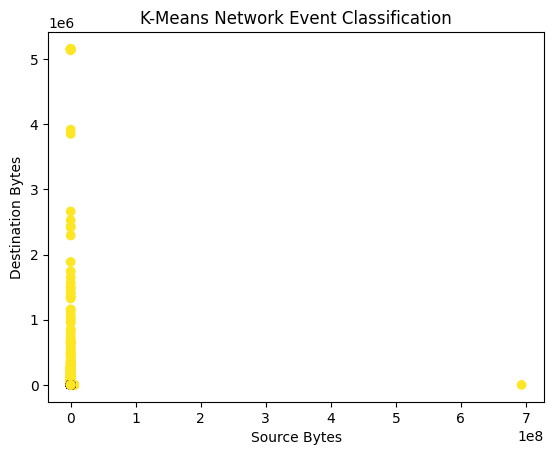

In [ ]:

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load KDD Cup 99 dataset
data = fetch_kddcup99(percent10=True, shuffle=True, random_state=42)

df = pd.DataFrame(data.data)
df.columns = data.feature_names

# Select numerical network features
X = df.iloc[:, [0, 4, 5, 22, 23]].astype(float)

# Get actual labels for comparison
y = np.array([
    "Normal" if label == b"normal." else "Abnormal"
    for label in data.target
])

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Map clusters to normal and abnormal
mapping = {}
for c in range(2):
    mapping[c] = pd.Series(y[clusters == c]).mode()[0]

df["Cluster"] = clusters
df["Category"] = [mapping[c] for c in clusters]

# Display results
print("Dataset:", "KDD Cup 99")
print("Total Network Events:", len(df))
print("\nClassification Results:")
print(df[["Cluster", "Category"]].head(10))

print("\nCategory Summary:")
print(df["Category"].value_counts())

# Visualise clusters
plt.scatter(X.iloc[:, 1], X.iloc[:, 2], c=clusters)
plt.xlabel("Source Bytes")
plt.ylabel("Destination Bytes")
plt.title("K-Means Network Event Classification")
plt.show()
